# 20 - Índices espectrais e features de radar

| | |
|---|---|
| **Tarefa do plano** | S2-02 (harmonização Landsat) e S2-03 (índices NDWI, MNDWI, NDVI, NDMI + ΔVV e rácio VV/VH) |
| **O que faz** | Transforma as bandas dos satélites em números que realçam a água |
| **Usa** | Landsat, Sentinel-2 e Sentinel-1 mensais (Semana 1) |
| **Produz** | `data/interim/features/` (referência seca do radar, rasters de índices dos meses escolhidos) |

**Ideia simples.** Uma imagem de satélite tem várias bandas (cores, incluindo
infravermelho). A água reflete pouco infravermelho, por isso combinar duas bandas
numa fração dá um número que separa bem a água do resto.

| Índice | Fórmula | Como ler |
|---|---|---|
| NDWI | (verde − NIR) / (verde + NIR) | acima de 0: água |
| MNDWI | (verde − SWIR1) / (verde + SWIR1) | acima de 0: água; melhor junto a zonas construídas |
| NDVI | (NIR − vermelho) / (NIR + vermelho) | alto: vegetação densa |
| NDMI | (NIR − SWIR1) / (NIR + SWIR1) | alto: vegetação ou solo húmidos |
| VV, VH | radar em dB | muito negativo (escuro): água calma |
| ΔVV | VV do mês − VV da época seca | muito negativo: apareceu água nova |
| VV − VH | rácio em dB | ajuda a separar água de vegetação alagada |

Os índices são contas rápidas. Por isso **não** se guardam para todos os meses
(duplicaria vários GB): são calculados na hora quando se monta a tabela de treino,
e exportados como raster só para os meses que se quer abrir no QGIS.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, drivers, features, rasters, series, training
from ete import grid as G

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_2")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Harmonização Landsat (S2-02): testada e não aplicada

O plano previa ajustar o Landsat 5/7 à escala do Landsat 8 com os coeficientes de
Roy et al. (2016). Foi testado sobre a área de estudo, no Earth Engine, comparando
Landsat 7 e Landsat 8 nos mesmos píxeis em duas épocas secas:

| Época seca | Zona | MNDWI Landsat 8 | MNDWI Landsat 7 sem harmonizar | MNDWI Landsat 7 harmonizado |
|---|---|---|---|---|
| 2013 | água | 0,68 | 0,68 | 0,16 |
| 2014 | água | 0,75 | 0,64 | 0,15 |
| 2013 | terra | −0,55 | −0,51 | −0,53 |
| 2014 | terra | −0,54 | −0,50 | −0,52 |

**Leitura.** Em terra a harmonização quase não muda nada. Na água estraga o
sinal: os coeficientes somam um valor fixo às bandas de infravermelho, que na
água são quase zero, e o índice de água cai de cerca de 0,68 para 0,16. Num
projeto de cheias isso é inaceitável, por isso as composições foram descarregadas
**sem** harmonização (`harmonize_tm_etm_to_oli: false` no config). Esta decisão
deve constar na metodologia do relatório OAD.

## 2. Referência seca do radar

Para cada píxel, a mediana do VV e do VH de todos os meses secos (junho a
setembro). É a imagem do "normal sem cheia" com que cada mês é comparado.

data/interim/features/sentinel1_dry_reference_marracuene_10m.tif (45 MB)
meses secos usados por píxel (mediana): 48


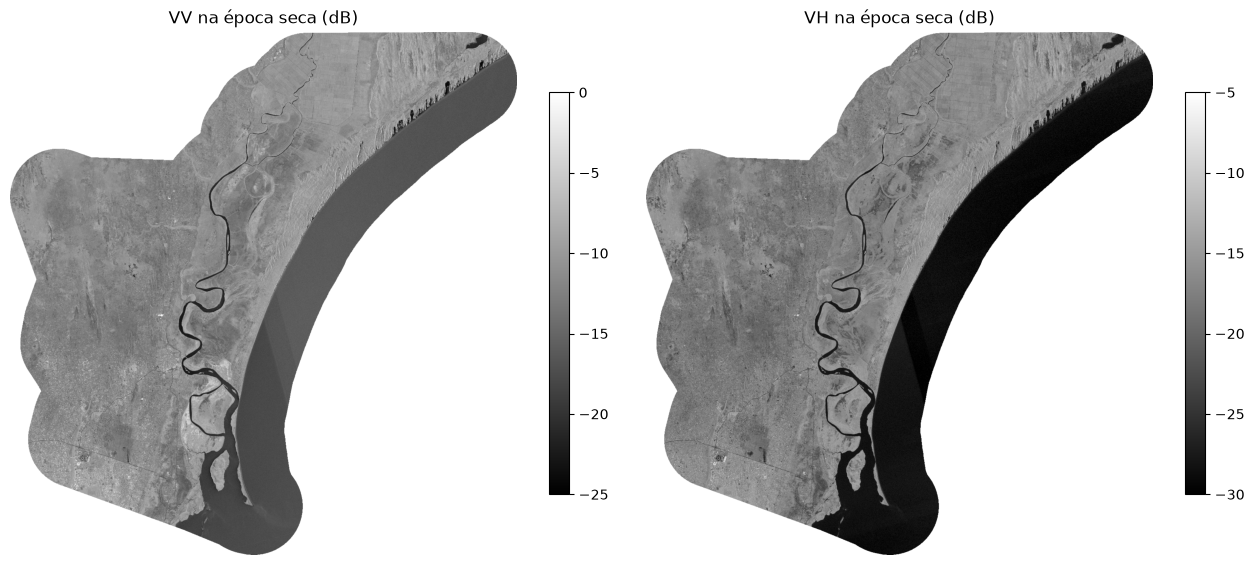

In [2]:
ref_file = rasters.s1_dry_reference_file(cfg)
if not ref_file.exists():
    rasters.build_s1_dry_reference(cfg)          # alguns minutos, só da primeira vez
ref = rasters.read_bands(ref_file)
print(ref_file.relative_to(ROOT), f"({ref_file.stat().st_size / 1e6:.0f} MB)")
print("meses secos usados por píxel (mediana):", int(np.nanmedian(ref["n_months"][ref["n_months"] > 0])))

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, band, lim in zip(axes, ["VV", "VH"], [(-25, 0), (-30, -5)]):
    im = ax.imshow(ref[band][::4, ::4], cmap="gray", vmin=lim[0], vmax=lim[1])
    ax.set_title(f"{band} na época seca (dB)"); ax.axis("off"); plt.colorbar(im, ax=ax, shrink=0.6)
plt.tight_layout()

## 3. Um mês de cheia contra um mês seco

Fevereiro de 2023 foi o mês mais chuvoso dos 20 anos. Compara-se com agosto de
2022. No painel ΔVV, o azul mostra onde o radar ficou mais escuro do que o normal
da época seca, ou seja, onde apareceu água.

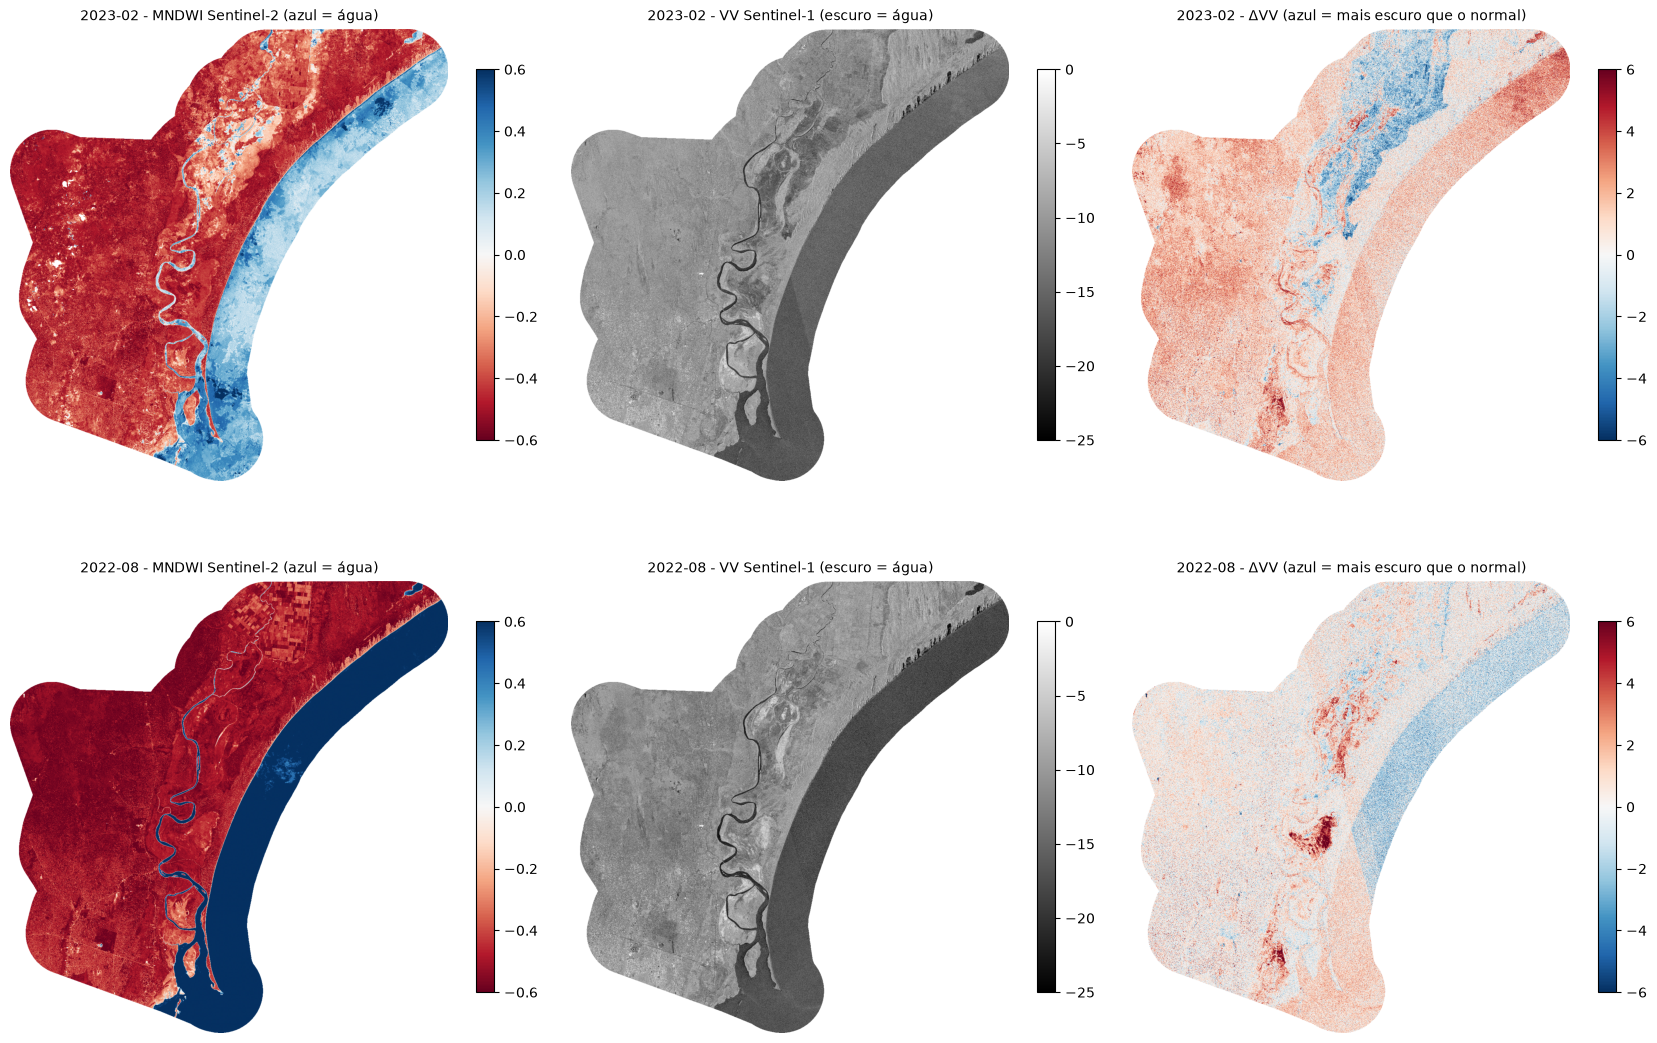

In [3]:
WET, DRY = "2023-02", "2022-08"

def month_panels(month):
    s2 = rasters.read_bands(rasters.monthly_file(cfg, "sentinel2", month), ["green", "swir1"])
    mndwi = features.optical_indices(s2["green"], s2["green"], s2["green"], s2["green"], s2["swir1"], s2["swir1"])["mndwi"][::4, ::4]
    s1 = rasters.read_bands(rasters.monthly_file(cfg, "sentinel1", month), ["VV"])
    return mndwi, s1["VV"][::4, ::4], (s1["VV"] - ref["VV"])[::4, ::4]

fig, axes = plt.subplots(2, 3, figsize=(17, 12))
for row, month in zip(axes, [WET, DRY]):
    mndwi, vv, dvv = month_panels(month)
    for ax, data, title, kw in zip(row, [mndwi, vv, dvv], ["MNDWI Sentinel-2 (azul = água)", "VV Sentinel-1 (escuro = água)", "ΔVV (azul = mais escuro que o normal)"],
                                   [dict(cmap="RdBu", vmin=-0.6, vmax=0.6), dict(cmap="gray", vmin=-25, vmax=0), dict(cmap="RdBu_r", vmin=-6, vmax=6)]):
        im = ax.imshow(data, **kw); ax.set_title(f"{month} - {title}", fontsize=10); ax.axis("off")
        plt.colorbar(im, ax=ax, shrink=0.6)
plt.tight_layout()
plt.savefig(REPORTS / "20_cheia_vs_seco.png", dpi=110)

## 4. Um limiar simples de radar não chega: o que os dados mostram

Tentativa: contar, em cada mês, a área onde o VV caiu pelo menos 3 dB em relação
à época seca **e** ficou tão escuro como água (−16 dB ou menos), fora da água
permanente. Antes disso retira-se o desvio geral do mês (`s1_offset_vv`), medido
em terreno alto que nunca inunda.

month,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
s1_offset_vv,0.600,-0.290,0.280,0.060,0.240,0.190,0.320,0.460,0.440,0.300,0.420,0.610
s1_new_water_km2,52.830,53.220,26.900,10.860,11.680,7.970,7.970,6.020,13.170,11.450,6.380,26.300


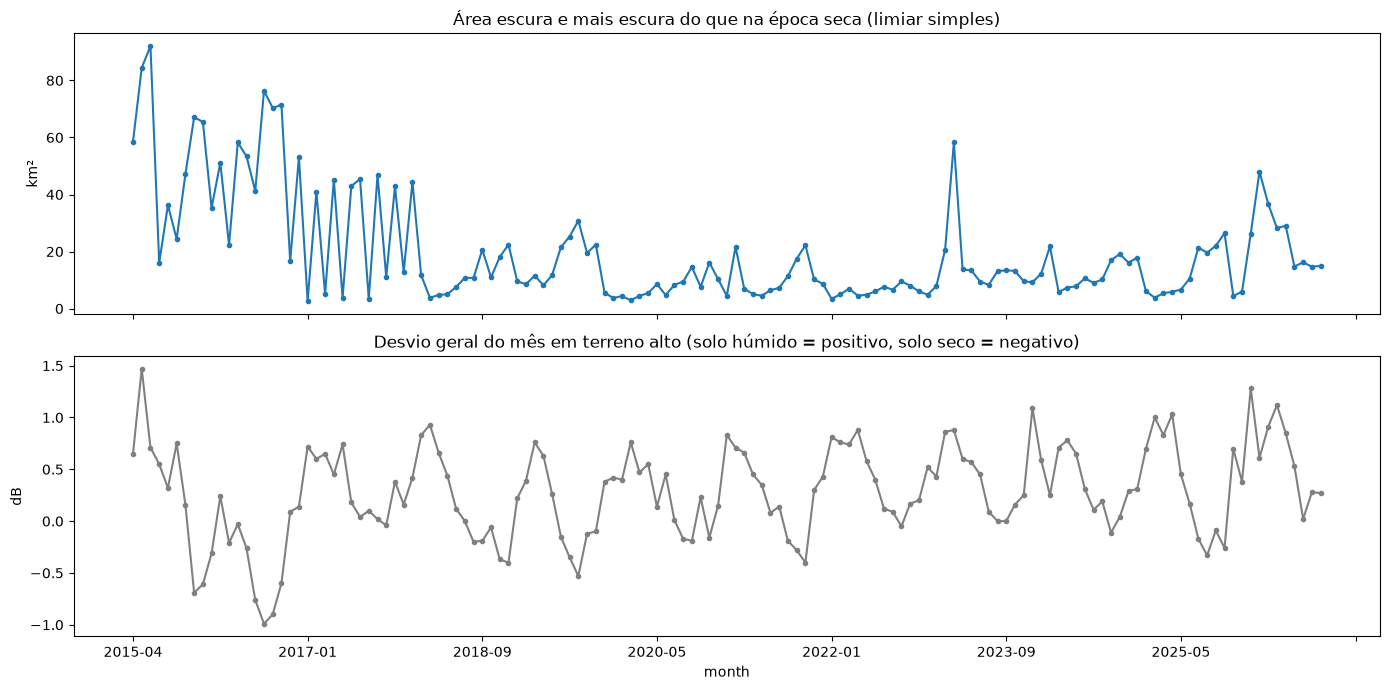

In [4]:
change_file = drivers.table(cfg, "s1_change_monthly")
if not change_file.exists():
    rasters.s1_change_series(cfg).round(4).to_csv(change_file)       # alguns minutos, só da primeira vez
change = pd.read_csv(change_file, index_col=0)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
change["s1_new_water_km2"].plot(ax=axes[0], marker=".", ylabel="km²", title="Área escura e mais escura do que na época seca (limiar simples)")
change["s1_offset_vv"].plot(ax=axes[1], marker=".", color="grey", ylabel="dB", title="Desvio geral do mês em terreno alto (solo húmido = positivo, solo seco = negativo)")
plt.tight_layout(); plt.savefig(REPORTS / "20_radar_limiar_simples.png", dpi=110)
change.groupby(change.index.str[:4])[["s1_offset_vv", "s1_new_water_km2"]].median().round(2).T

**Leitura honesta deste gráfico.** Os valores mais altos não são as cheias de
2021, 2023 ou 2026: são 2015 e 2016. Há duas razões, e ambas importam para o
Modelo B:

1. **Seca de 2015–2016.** Solo nu, seco e liso também reflete muito pouco o
   radar. Numa planície de inundação ressequida, o radar fica escuro como se
   fosse água. Um limiar de VV sozinho confunde seca com cheia.
2. **Duas órbitas misturadas.** Cada composição mensal junta passagens de duas
   órbitas (órbitas relativas 145 e 72), com cerca de 10° de diferença no ângulo
   de incidência. Em 2015 só existe a órbita 145 (ângulo de 44,6°, contra cerca
   de 38° nos outros anos), e superfícies lisas ficam mais escuras a ângulos
   maiores. A receita da Semana 1 fixou a **direção** da órbita (ascendente), mas
   não a **órbita relativa**.

**Consequências práticas**

- A deteção de água precisa de várias features em conjunto (VV, VH, rácio,
  ótico, terreno) e de rótulos: é isso que o Modelo B faz. Um limiar fixo de ΔVV
  não deve ser usado como detetor nem como gatilho de alertas.
- A tabela de treino inclui o ângulo (`s1_angle`) e a mudança sem o desvio do mês
  (`dvv_rel`, `dvh_rel`), para o modelo poder compensar.
- Os meses de 2015 devem ser tratados com cuidado no treino do Modelo B (ângulo
  diferente de todos os outros anos).
- A correção de fundo seria descarregar de novo o Sentinel-1 só com a órbita
  145 (cerca de 6,7 GB de internet). É uma decisão da equipa; ver o resumo.

## 5. Exportar os índices de meses escolhidos (para o QGIS)

Escreve os rasters de índices dos meses da lista em
`data/interim/features/indices/<mês>/`. Acrescentar à lista os meses que se quer
ver no QGIS ou usar no workshop.

In [5]:
EXPORT_MONTHS = ["2023-02", "2022-08"]
for month in EXPORT_MONTHS:
    for file in rasters.export_month_features(cfg, month):
        print(file.relative_to(ROOT), f"({file.stat().st_size / 1e6:.0f} MB)")

data/interim/features/indices/2023-02/landsat_indices_marracuene_2023-02_30m.tif (17 MB)
data/interim/features/indices/2023-02/sentinel2_indices_marracuene_2023-02_10m.tif (151 MB)
data/interim/features/indices/2023-02/sentinel1_features_marracuene_2023-02_10m.tif (113 MB)


data/interim/features/indices/2022-08/landsat_indices_marracuene_2022-08_30m.tif (16 MB)
data/interim/features/indices/2022-08/sentinel2_indices_marracuene_2022-08_10m.tif (148 MB)
data/interim/features/indices/2022-08/sentinel1_features_marracuene_2022-08_10m.tif (113 MB)
